In [4]:
import shap
import pandas as pd
import joblib

# Load XGBoost v2 (the MICE-cleaned version, which is what we actually saved in this project)
model = joblib.load("../models/xgboost_v2_mice.pkl")

# Load validation data
val_df = pd.read_parquet("../data/processed/val_final.parquet")

print("SHAP version:", shap.__version__)
print("Model and data loaded")

SHAP version: 0.52.0
Model and data loaded


In [5]:
# Same feature columns we used for training
exclude_cols = ["patient_id", "SepsisLabel"]
feature_cols = [c for c in val_df.columns if c not in exclude_cols]

# Take a smaller sample from validation set for faster SHAP computation
# (SHAP can be slow on very large datasets)
sample_val = val_df[feature_cols].sample(2000, random_state=42)

# Create a SHAP explainer specifically designed for tree-based models like XGBoost
explainer = shap.TreeExplainer(model)

# Calculate SHAP values for our sample - this tells us how much each feature
# contributed to each individual prediction
shap_values = explainer.shap_values(sample_val)

print("SHAP values calculated, shape:", shap_values.shape)

SHAP values calculated, shape: (2000, 71)


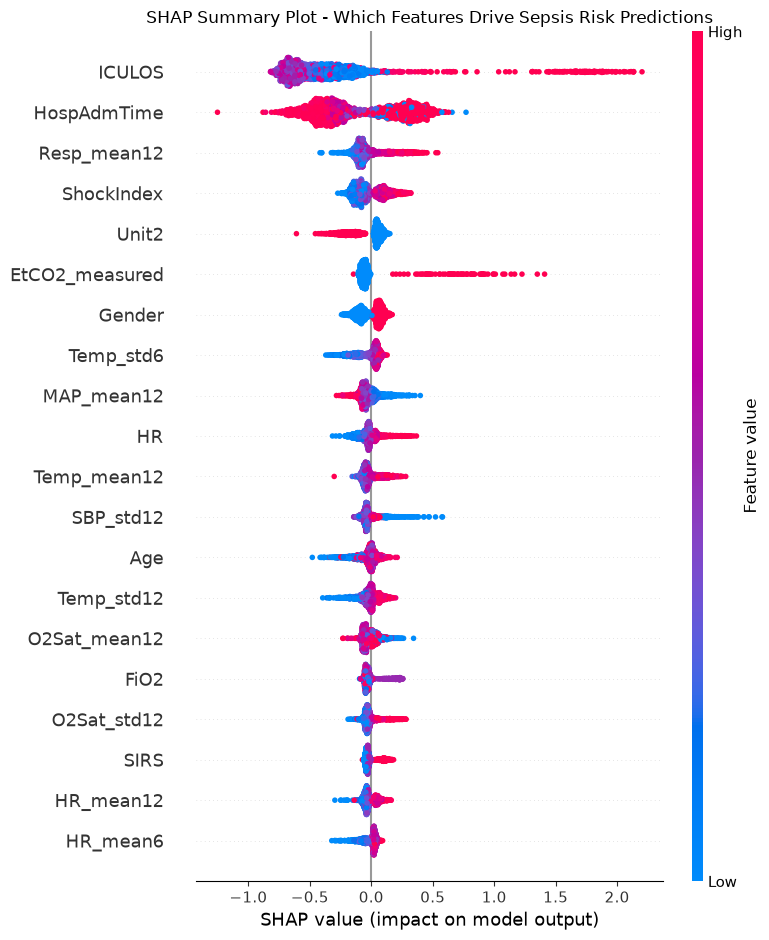

In [6]:
import matplotlib.pyplot as plt

# Create a summary plot showing which features matter most, and how their values affect the prediction
shap.summary_plot(shap_values, sample_val, show=False)

plt.title("SHAP Summary Plot - Which Features Drive Sepsis Risk Predictions")
plt.tight_layout()
plt.show()